# 04 — Ghi chú khám phá (Exploration Notes)

**Mục tiêu:** tổng hợp các phát hiện từ notebook 01–03 thành **chỉ số chính**, **bảng hành động**
(NCC/sản phẩm cần chú ý) và **giả thuyết** cho bước phân tích tiếp theo.
Mọi con số trong notebook này đều tính trực tiếp từ `analytics.db` qua `sql/queries/`, nên chạy lại
là cập nhật theo dữ liệu.

| Mục | Truy vấn |
|---|---|
| KPI toàn chuỗi | `classification_summary`, `vendor_kpi`, `po_metrics`, `inventory_status` |
| NCC chủ lực | `top_vendors` |
| Sản phẩm bán chạy | `top_brands` |
| Hàng chậm luân chuyển | `slow_moving_brands` |
| Ứng viên khuyến mãi | `promo_candidates` |

## 0. Thiết lập môi trường
Thêm thư mục gốc dự án vào `sys.path` để import package `src`, nạp thư viện và áp dụng
phong cách biểu đồ xuất bản (bảng màu **đậm**) dùng chung cho mọi notebook.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl, preprocessing as pp, visualization as viz
from src.config import TABLE_DIR
from src.visualization import PALETTE, CLASS_COLORS

viz.set_style()
TABLE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Bảng chỉ số chính (KPI) toàn chuỗi

Tính các KPI cấp chuỗi từ các mart: doanh thu, tiền mua, lợi nhuận gộp, phí vận chuyển,
biên, vòng quay, lead time, thời gian thanh toán, mức tập trung NCC.

In [2]:
cls = dl.query("classification_summary")
vendors = dl.query("vendor_kpi", min_sales=0)
po = dl.query("po_metrics")
inv = dl.query("inventory_status")

total_sales, total_purchase = cls["sales_dollars"].sum(), cls["purchase_dollars"].sum()
gross = cls["gross_profit"].sum()
freight = po["Freight"].sum()
kpi = pd.Series({
    "Doanh thu (USD)": total_sales,
    "Tiền mua (USD)": total_purchase,
    "Lợi nhuận gộp (USD)": gross,
    "Biên LN gộp (%)": gross / total_sales * 100,
    "Phí vận chuyển (USD)": freight,
    "Phí VC / tiền mua (%)": freight / total_purchase * 100,
    "LN gộp sau phí VC (USD)": gross - freight,
    "Thuế tiêu thụ thu hộ (USD)": cls["excise"].sum(),
    "Số NCC có doanh thu": int((vendors["sales_dollars"] > 0).sum()),
    "Số NCC tạo 80% doanh thu": pp.n_to_reach_share(vendors["cum_sales_share_pct"], 80),
    "Lead time TB (ngày)": po["lead_days"].mean(),
    "Thời gian thanh toán TB (ngày)": po["pay_days"].mean(),
    "% PO lệch số lượng hóa đơn": po["qty_mismatch"].mean() * 100,
    "Giá trị tồn đầu kỳ (USD)": inv["begin_value"].sum(),
    "Giá trị tồn cuối kỳ (USD)": inv["end_value"].sum(),
})
kpi.to_frame("giá trị").to_csv(TABLE_DIR / "04_kpi_overview.csv")
kpi.map("{:,.2f}".format).to_frame("giá trị")

,giá trị
Doanh thu (USD),"452,062,952.02"
Tiền mua (USD),"321,900,765.53"
Lợi nhuận gộp (USD),"130,162,186.49"
Biên LN gộp (%),28.79
Phí vận chuyển (USD),"1,640,474.69"
Phí VC / tiền mua (%),0.51
LN gộp sau phí VC (USD),"128,521,711.80"
Thuế tiêu thụ thu hộ (USD),"18,974,240.74"
Số NCC có doanh thu,127.00
Số NCC tạo 80% doanh thu,18.00


So sánh hai nhóm sản phẩm (rượu mạnh / rượu vang) — tỷ trọng doanh thu, biên và vòng quay.

In [3]:
cls.assign(sales_share_pct=cls["sales_dollars"] / total_sales * 100)

,Classification,ClassName,n_brands,purchase_dollars,sales_dollars,gross_profit,margin_pct,stock_turnover,excise,sales_share_pct
0,1,Rượu mạnh,3342,"216,964,832.50","290,165,010.18","73,200,177.68",25.23,0.98,"17,074,575.80",64.19
1,2,Rượu vang,8108,"104,935,933.03","161,897,941.84","56,962,008.81",35.18,0.98,"1,899,664.94",35.81


**Biểu đồ 4.1 — Thác lợi nhuận (waterfall):** doanh thu → trừ tiền mua → trừ phí vận chuyển →
lợi nhuận còn lại. (Thuế tiêu thụ được hiển thị tham khảo, không trừ vì chưa rõ có nằm trong
doanh thu hay không.)

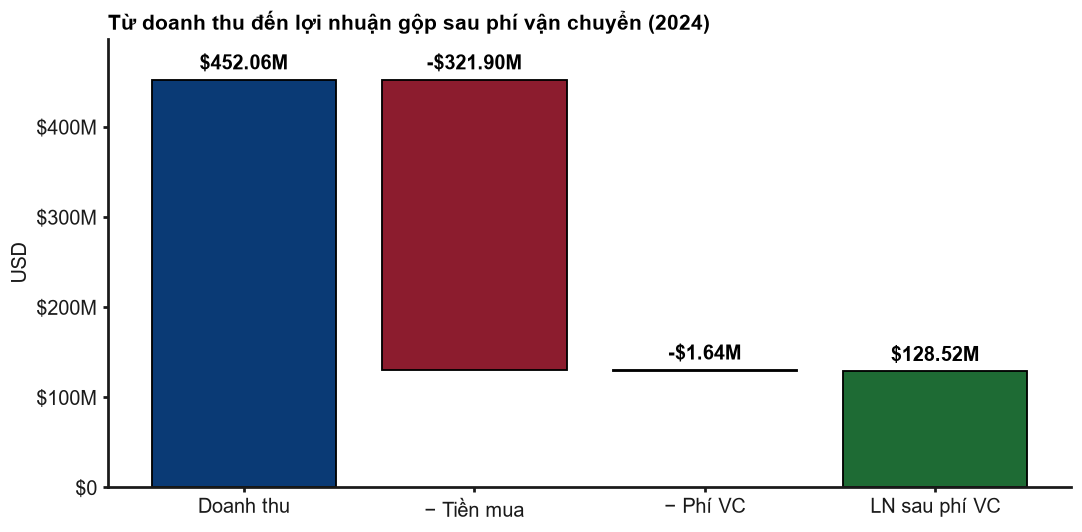

In [4]:
steps = [("Doanh thu", total_sales), ("− Tiền mua", -total_purchase), ("− Phí VC", -freight)]
fig, (ax,) = viz.new_figure(figsize=(10, 5))
run = 0
for i, (name, val) in enumerate(steps):
    h = abs(val)
    ax.bar(i, h, bottom=run + val if val < 0 else 0, color=PALETTE["blue"] if val > 0 else PALETTE["wine"],
           edgecolor="black", linewidth=1.2)
    top = max(run, run + val)                       # đỉnh của thanh hiện tại
    ax.text(i, top + total_sales * 0.015, pp.fmt_money(val), ha="center", va="bottom", fontweight="bold")
    run += val
ax.bar(len(steps), run, color=PALETTE["green"], edgecolor="black", linewidth=1.2)
ax.text(len(steps), run + total_sales * 0.015, pp.fmt_money(run), ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, total_sales * 1.1)
ax.set_xticks(range(len(steps) + 1), [s[0] for s in steps] + ["LN sau phí VC"])
viz.fmt_axis(ax, y="money")
viz.label(ax, "Từ doanh thu đến lợi nhuận gộp sau phí vận chuyển (2024)", None, "USD")
viz.save_figure(fig, "04_profit_waterfall")
plt.show()

## 2. NCC chủ lực

Top 10 NCC theo doanh thu cùng biên, % phí vận chuyển, vòng quay, lead time. Lưu CSV.

In [5]:
topv = dl.query("top_vendors", top_n=10)
topv.to_csv(TABLE_DIR / "04_top_vendors.csv", index=False)
pp.style_table(topv.drop(columns=["VendorNumber"]),
               money=["sales_dollars", "purchase_dollars", "gross_profit", "freight"],
               pct=["margin_pct", "freight_pct", "sales_share_pct", "purchase_share_pct", "cum_sales_share_pct"],
               dec=["stock_turnover", "avg_lead_days", "avg_pay_days"], num=["n_brands"])

VendorName,n_brands,sales_dollars,purchase_dollars,gross_profit,margin_pct,freight,freight_pct,stock_turnover,sales_share_pct,purchase_share_pct,cum_sales_share_pct,avg_lead_days,avg_pay_days
DIAGEO NORTH AMERICA INC,416,"$68,742,417","$50,959,797","$17,782,620",25.9%,"$257,032",0.5%,0.99,15.2%,15.8%,15.2%,11.11,35.62
MARTIGNETTI COMPANIES,"1,520","$41,047,306","$27,861,690","$13,185,616",32.1%,"$144,929",0.5%,0.98,9.1%,8.7%,24.3%,10.60,37.15
PERNOD RICARD USA,254,"$32,281,248","$24,124,092","$8,157,156",25.3%,"$123,780",0.5%,0.98,7.1%,7.5%,31.4%,11.15,36.07
JIM BEAM BRANDS COMPANY,389,"$31,906,321","$24,203,151","$7,703,169",24.1%,"$123,881",0.5%,0.96,7.1%,7.5%,38.5%,11.11,35.67
BACARDI USA INC,172,"$25,014,557","$17,624,379","$7,390,178",29.5%,"$89,286",0.5%,1.02,5.5%,5.5%,44.0%,11.33,34.78
CONSTELLATION BRANDS INC,465,"$24,469,173","$15,573,918","$8,895,255",36.4%,"$79,529",0.5%,0.99,5.4%,4.8%,49.4%,11.29,36.29
E & J GALLO WINERY,513,"$18,556,086","$12,289,608","$6,266,478",33.8%,"$61,967",0.5%,0.97,4.1%,3.8%,53.5%,11.20,36.55
BROWN-FORMAN CORP,135,"$18,478,557","$13,529,433","$4,949,124",26.8%,"$68,602",0.5%,0.98,4.1%,4.2%,57.6%,10.85,36.16
ULTRA BEVERAGE COMPANY LLP,905,"$17,822,938","$13,210,614","$4,612,325",25.9%,"$68,055",0.5%,0.97,3.9%,4.1%,61.6%,11.78,35.69
M S WALKER INC,898,"$15,465,248","$10,935,817","$4,529,430",29.3%,"$55,552",0.5%,0.98,3.4%,3.4%,65.0%,11.40,35.60


**Biểu đồ 4.2 — Top 10 NCC: tỷ trọng doanh thu vs tỷ trọng tiền mua.** NCC có tỷ trọng mua
> tỷ trọng bán đang “giữ” nhiều vốn hơn mức đóng góp doanh thu.

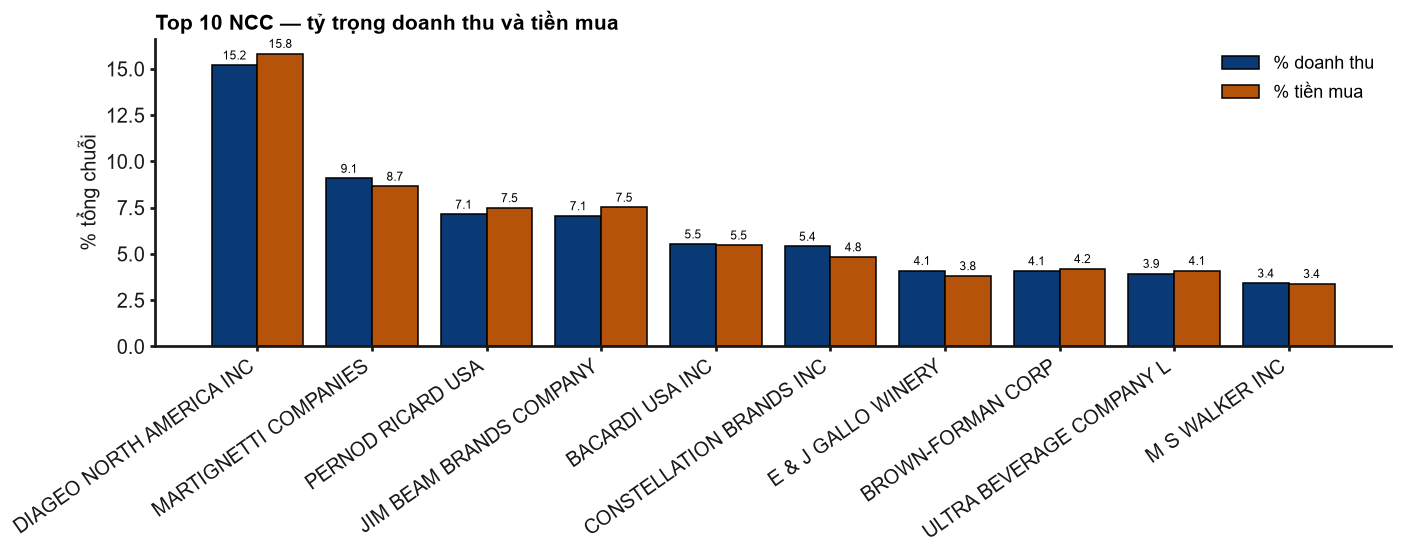

In [6]:
names = [n[:24] for n in topv["VendorName"]]
fig, (ax,) = viz.new_figure(figsize=(13, 5.2))
viz.bar(ax, names, {"% doanh thu": topv["sales_share_pct"], "% tiền mua": topv["purchase_share_pct"]},
        colors=[PALETTE["blue"], PALETTE["orange"]], annotate="{:.1f}", fontsize=8)
ax.tick_params(axis="x", rotation=35)
for t in ax.get_xticklabels():
    t.set_ha("right")
viz.label(ax, "Top 10 NCC — tỷ trọng doanh thu và tiền mua", None, "% tổng chuỗi")
viz.save_figure(fig, "04_top_vendors_share")
plt.show()

## 3. Sản phẩm cần hành động

Top 15 sản phẩm bán chạy nhất (doanh thu) — nhóm cần đảm bảo không đứt hàng.

In [7]:
topb = dl.query("top_brands", top_n=15)
topb.to_csv(TABLE_DIR / "04_top_brands.csv", index=False)
pp.style_table(topb, money=["sales_dollars", "purchase_dollars", "gross_profit"], pct=["margin_pct"],
               dec=["RetailPrice", "stock_turnover"], num=["sales_qty", "n_stores_sold", "Brand"])

Brand,Description,VendorName,ClassName,RetailPrice,sales_qty,sales_dollars,purchase_dollars,gross_profit,margin_pct,stock_turnover,n_stores_sold
"1,233",Jack Daniels No 7 Black,BROWN-FORMAN CORP,Rượu mạnh,36.99,"142,049","$5,101,920","$3,811,252","$1,290,668",25.3%,0.98,79
"3,405",Tito's Handmade Vodka,MARTIGNETTI COMPANIES,Rượu mạnh,28.99,"160,247","$4,819,073","$3,804,041","$1,015,032",21.1%,0.98,79
"8,068",Absolut 80 Proof,PERNOD RICARD USA,Rượu mạnh,24.99,"187,140","$4,538,121","$3,418,304","$1,119,817",24.7%,1.00,80
"4,261",Capt Morgan Spiced Rum,DIAGEO NORTH AMERICA INC,Rượu mạnh,22.99,"200,412","$4,475,973","$3,261,198","$1,214,775",27.1%,0.99,79
"3,545",Ketel One Vodka,DIAGEO NORTH AMERICA INC,Rượu mạnh,29.99,"135,838","$4,223,108","$3,023,206","$1,199,902",28.4%,0.98,79
"3,858",Grey Goose Vodka,BACARDI USA INC,Rượu mạnh,23.99,"141,860","$3,383,912","$2,466,636","$917,276",27.1%,1.02,80
"2,589",Jameson Irish Whiskey,PERNOD RICARD USA,Rượu mạnh,39.99,"69,627","$2,773,368","$2,177,285","$596,083",21.5%,0.98,79
"3,489",Tanqueray,DIAGEO NORTH AMERICA INC,Rượu mạnh,27.99,"90,481","$2,640,491","$1,903,740","$736,752",27.9%,0.99,79
"3,102",Smirnoff Traveler,DIAGEO NORTH AMERICA INC,Rượu mạnh,17.99,"148,265","$2,592,041","$2,088,335","$503,707",19.4%,0.92,79
"1,376",Jim Beam,JIM BEAM BRANDS COMPANY,Rượu mạnh,21.99,"107,061","$2,435,393","$1,773,427","$661,966",27.2%,0.98,80


Hàng **chậm luân chuyển**: vòng quay < 0,5 (bán chưa tới nửa lượng mua), xếp theo giá vốn hàng
chưa bán ước tính = (SL mua − SL bán) × giá mua.

In [8]:
slow = dl.query("slow_moving_brands", max_turnover=0.5, top_n=15)
slow.to_csv(TABLE_DIR / "04_slow_moving_brands.csv", index=False)
all_slow = dl.query("slow_moving_brands", max_turnover=0.5, top_n=100000)
print(f"{len(all_slow):,} sản phẩm vòng quay < 0,5 — giá vốn tồn ước tính {pp.fmt_money(all_slow['unsold_cost_est'].sum())}")
pp.style_table(slow, money=["purchase_dollars", "sales_dollars", "unsold_cost_est"],
               dec=["RetailPrice", "PurchasePrice", "stock_turnover"], num=["purchase_qty", "sales_qty", "Brand"])

1,280 sản phẩm vòng quay < 0,5 — giá vốn tồn ước tính $3.32M


Brand,Description,VendorName,ClassName,RetailPrice,PurchasePrice,purchase_qty,sales_qty,purchase_dollars,sales_dollars,stock_turnover,unsold_cost_est
"2,277",Kilbeggan Irish Whiskey,JIM BEAM BRANDS COMPANY,Rượu mạnh,22.99,17.03,"4,244","1,546","$72,275","$20,273",0.36,"$45,947"
"4,785",Remy Martin XO Excellence,REMY COINTREAU USA INC,Rượu mạnh,74.99,53.95,"1,101",274,"$59,399","$21,237",0.25,"$44,617"
"27,031",Opus One 2013,MARTIGNETTI COMPANIES,Rượu vang,264.99,180.27,402,198,"$72,469","$52,468",0.49,"$36,775"
"2,289",Whistle Pig Boss Hog Rye,PERFECTA WINES,Rượu mạnh,298.99,239.19,186,37,"$44,489","$11,063",0.20,"$35,639"
"3,365",Russian Standard Vodka,Russian Standard Vodka,Rượu mạnh,24.99,18.65,"2,244",503,"$41,851","$12,570",0.22,"$32,470"
"5,609",Integre Vodka,M S WALKER INC,Rượu mạnh,5.99,4.68,"7,171",430,"$33,560","$2,576",0.06,"$31,548"
"6,904",Westland Trinity 3 Pack,ULTRA BEVERAGE COMPANY LLP,Rượu mạnh,74.99,57.68,612,82,"$35,300","$6,149",0.13,"$30,570"
"15,880",San Polo Brun di Montlcno 11,SOUTHERN WINE & SPIRITS NE,Rượu vang,74.99,48.69,600,2,"$29,214",$150,0.00,"$29,117"
"2,204",Bowmore 25 Yr Single Malt,JIM BEAM BRANDS COMPANY,Rượu mạnh,429.99,318.51,85,6,"$27,073","$2,580",0.07,"$25,162"
"9,116",KAH Tequila 3/50mLs Pak,ULTRA BEVERAGE COMPANY LLP,Rượu mạnh,24.99,18.51,"1,560",205,"$28,876","$5,123",0.13,"$25,081"


**Ứng viên khuyến mãi**: doanh thu thuộc 25 % thấp nhất nhưng biên thuộc 25 % cao nhất —
lợi nhuận/đơn vị tốt, có thể tăng trưng bày hoặc khuyến mãi để đẩy số lượng.

In [9]:
promo = dl.query("promo_candidates", sales_pct=0.25, margin_pct=0.75)
promo.to_csv(TABLE_DIR / "04_promo_candidates.csv", index=False)
print(f"{len(promo):,} sản phẩm ứng viên")
promo.head(15)

524 sản phẩm ứng viên


,Brand,Description,VendorName,ClassName,RetailPrice,sales_dollars,gross_profit,margin_pct,stock_turnover,sales_prank,margin_prank
0,3065,Three Olives Grape Vodka,PROXIMO SPIRITS INC.,Rượu mạnh,0.99,85.14,84.43,99.17,86.00,0.04,1.00
1,6127,The Club Strawbry Margarita,DIAGEO NORTH AMERICA INC,Rượu mạnh,1.99,143.28,141.81,98.97,72.00,0.07,1.00
2,8151,St Elder Elderflower Liqueur,M S WALKER INC,Rượu mạnh,0.99,410.85,405.17,98.62,51.88,0.17,1.00
3,12253,Cecchi Natio Organic Chianti,ULTRA BEVERAGE COMPANY LLP,Rượu vang,14.99,735.08,724.64,98.58,46.00,0.24,1.00
4,788,Skinnygirl Cucumber Vodka,JIM BEAM BRANDS COMPANY,Rượu mạnh,14.99,779.48,768.29,98.56,52.00,0.24,1.00
5,4357,Bacardi Oakheart Spiced Trav,BACARDI USA INC,Rượu mạnh,9.99,399.60,392.14,98.13,40.00,0.17,1.00
6,8563,Chi Chi's Chocolate Malt RTD,SAZERAC NORTH AMERICA INC.,Rượu mạnh,10.99,461.58,452.86,98.11,42.00,0.18,1.00
7,1007,12 Days of Pearls Gift Set,LUXCO INC,Rượu mạnh,9.99,309.69,302.50,97.68,31.00,0.14,1.00
8,41231,Mad Dogs & Englishmen Jumil,PINE STATE TRADING CO,Rượu vang,9.99,279.80,273.27,97.67,20.00,0.13,1.00
9,3152,Three Olives Jacked Apple,PROXIMO SPIRITS INC.,Rượu mạnh,10.99,670.39,654.57,97.64,30.50,0.23,1.00


**Biểu đồ 4.3 — Ma trận doanh thu × biên** của mọi sản phẩm có bán, tô đậm các ứng viên khuyến
mãi (cam) và hàng chậm luân chuyển (đỏ rượu). Đường đứt = phân vị 25 % doanh thu và 75 % biên.

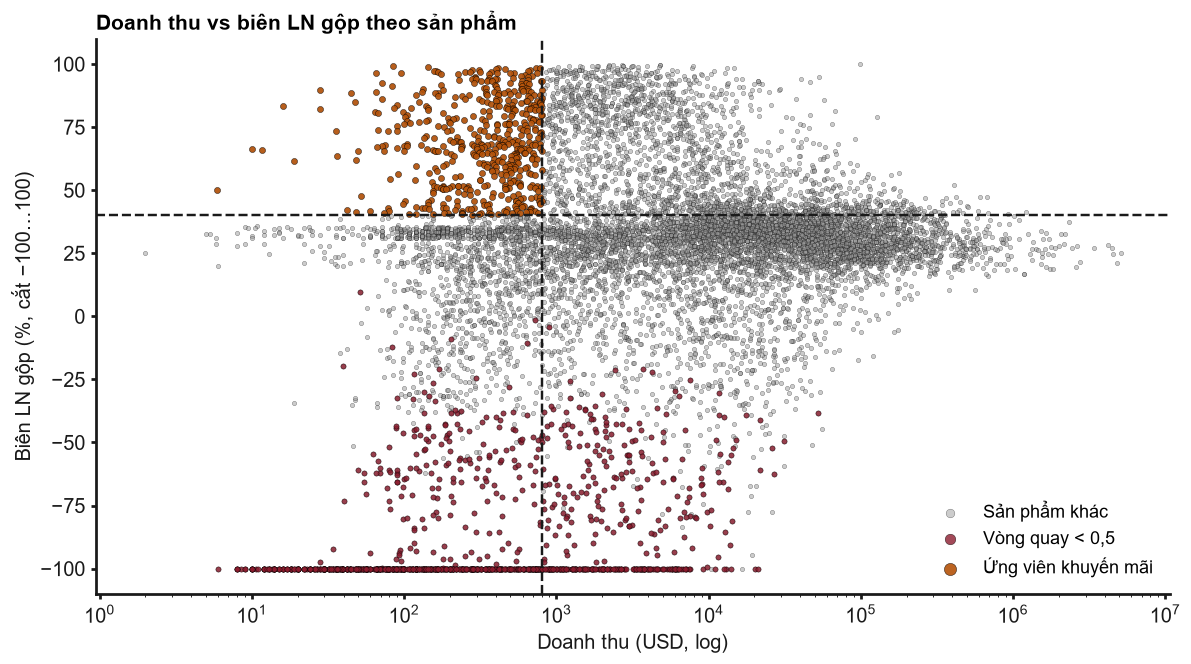

In [10]:
vb = dl.query("vendor_brand")
vb = vb[(vb["sales_dollars"] > 0) & vb["margin_pct"].notna()]
x_cut, y_cut = vb["sales_dollars"].quantile(0.25), vb["margin_pct"].quantile(0.75)
fig, (ax,) = viz.new_figure(figsize=(11, 6.2))
viz.scatter(ax, vb["sales_dollars"], vb["margin_pct"].clip(-100, 100), color=PALETTE["light_gray"], size=8, alpha=0.5, label="Sản phẩm khác")
slow_set = vb[vb["stock_turnover"] < 0.5]
viz.scatter(ax, slow_set["sales_dollars"], slow_set["margin_pct"].clip(-100, 100), color=PALETTE["wine"], size=12, alpha=0.8, label="Vòng quay < 0,5")
viz.scatter(ax, promo["sales_dollars"], promo["margin_pct"].clip(-100, 100), color=PALETTE["orange"], size=16, alpha=0.9, label="Ứng viên khuyến mãi")
ax.set_xscale("log")
ax.axvline(x_cut, color=PALETTE["dark"], ls="--", lw=1.6)
ax.axhline(y_cut, color=PALETTE["dark"], ls="--", lw=1.6)
ax.legend(markerscale=2, loc="lower right")
viz.label(ax, "Doanh thu vs biên LN gộp theo sản phẩm", "Doanh thu (USD, log)", "Biên LN gộp (%, cắt −100…100)")
viz.save_figure(fig, "04_brand_action_matrix")
plt.show()

## 4. Rủi ro dữ liệu cần nhớ khi phân tích tiếp
Các vấn đề có tỷ lệ ảnh hưởng lớn nhất (từ `dq_checks`) — cần ghi rõ cách xử lý trong báo cáo.

Lọc các vấn đề ảnh hưởng > 1 % số dòng.

In [11]:
dq = dl.query("dq_checks")
dq[dq["affected_pct"] > 1].sort_values("affected_pct", ascending=False)

,check_id,check_name,table_name,n_affected,n_total,affected_pct,action
8,7,Approval rỗng,vendor_invoice,5169,5543,93.25,"Coi là “chưa ghi nhận”, không impute"
2,1,VendorName có khoảng trắng thừa,vendor_invoice,5133,5543,92.60,TRIM()
1,1,VendorName có khoảng trắng thừa,purchase_prices,10407,12261,84.88,TRIM()
11,8,Sau ghép: PayDate hóa đơn ≠ PayDate trên dòng mua,mart_po,1339,5543,24.16,pay_days tính theo ngày trên hóa đơn
12,8,Số PO trên hóa đơn bị xáo trộn (ghép lại theo ...,vendor_invoice,1336,5543,24.10,"Nối hóa đơn qua map_invoice_po, không theo PON..."
10,8,Sau ghép: InvoiceDate hóa đơn ≠ InvoiceDate tr...,mart_po,1273,5543,22.97,pay_days tính theo ngày trên hóa đơn
15,10,GrossProfit < 0 (lỗ gộp),mart_vendor_brand,2127,11450,18.58,Không phải lỗi — phân tích riêng
18,13,PayDate sang 2025,vendor_invoice,677,5543,12.21,Hợp lệ (đơn vắt kỳ)
23,15,"Cặp (Brand, NCC) có bán nhưng không có dòng mu...",mart_vendor_brand,757,11450,6.61,Giữ lại (FULL JOIN) — bán từ tồn đầu kỳ
17,13,PODate trước 2024,purchases (PO),169,5543,3.05,Hợp lệ (đơn vắt kỳ)


## 5. Phát hiện chính & giả thuyết

**Phát hiện chính**

| # | Phát hiện | Bằng chứng |
|---|---|---|
| 1 | Doanh thu 2024 ≈ **452,1 triệu USD**, tiền mua ≈ 321,9 triệu, LN gộp ≈ 130,2 triệu (biên ~28,8 %); phí vận chuyển chỉ ~0,5 % tiền mua | Bảng KPI, biểu đồ 4.1 |
| 2 | Rượu mạnh tạo ~64 % doanh thu, rượu vang biên cao hơn (~35 % so với ~25 %) | `classification_summary` |
| 3 | Doanh thu tập trung: 18/129 NCC tạo 80 %; top 10 NCC có tỷ trọng mua ≈ tỷ trọng bán (không NCC lớn nào “giam vốn” rõ rệt) | Biểu đồ 3.4, 4.2 |
| 4 | 1 280 sản phẩm vòng quay < 0,5, giá vốn hàng chưa bán ước tính ~3,3 triệu USD | `slow_moving_brands` |
| 5 | 524 sản phẩm doanh thu thấp nhưng biên cao (ứng viên khuyến mãi) | `promo_candidates`, biểu đồ 4.3 |
| 6 | Mùa vụ mạnh, đỉnh tháng 7 và tháng 12; mua hàng bám theo mùa vụ | NB02 §8, NB03 §5 |

**Giả thuyết cho bước phân tích tiếp theo**

1. *H1 — Biên lợi nhuận theo quy mô NCC:* phí vận chuyển đã được xác nhận là tỷ lệ cố định ~0,5 % (không có
   lợi thế quy mô vận chuyển), vậy NCC lớn có biên gộp khác NCC nhỏ không? → so sánh biên giữa nhóm NCC
   lớn/nhỏ (Mann–Whitney), kiểm soát nhóm sản phẩm.
2. *H2 — Hàng chậm luân chuyển tập trung ở phân khúc giá cao:* vòng quay giảm theo phân khúc giá
   → kiểm định chi-bình phương giữa `PriceBand` và cờ `stock_turnover < 0,5`.
3. *H3 — Khuyến mãi sản phẩm biên cao:* nếu tăng SL bán của 524 ứng viên theo độ co giãn ≈ −0,9,
   lợi nhuận tăng thêm bao nhiêu? → mô phỏng kịch bản giảm giá 5–15 %.
4. *H4 — Chất lượng hóa đơn:* 1 336 hóa đơn (từ 25/09/2024) bị xáo trộn số PO và có ngày hóa đơn/thanh toán
   khác dòng mua; trước khi phân tích công nợ (`pay_days`) cần xác định nguồn ngày nào đúng và kiểm tra
   84 PO có phí vận chuyển > 1 % giá trị.

**Lưu ý phương pháp:** nguồn số liệu là 6 CSV gốc (không dùng `inventory.db`; `vendor_sales_summary.csv`
chỉ để kiểm chứng). “Vòng quay” = SL bán / SL mua (tỷ lệ bán/mua), không phải vòng quay kế toán. “Biên” và
“vòng quay” tính trên cả năm, chưa trừ tồn kho đầu kỳ — một
sản phẩm mua nhiều cuối năm sẽ bị đánh giá thấp. Thuế tiêu thụ chưa được trừ khỏi lợi nhuận vì chưa rõ
nó có nằm trong `SalesDollars` hay không.